# Predicting GPU task failure: a LightGBM baseline explained with SHAP

Can you tell, before a task starts, whether it will fail? This notebook trains a LightGBM classifier on 539,816
labelled tasks from the Alibaba PAI GPU trace, using ten features known at launch time (the task's resource
requests and the recent state of the machine it lands on), and explains it with SHAP. It then shows why the
headline score is misleading: the same model evaluated on users it has never seen does far worse, and part of what
it learned is a fingerprint of a few heavy users.

- Data: `kanvas_tasks_1h.parquet` from the dataset [alibaba-gpu-trace-2020](https://www.kaggle.com/datasets/swapnilshukla007/alibaba-gpu-trace-2020), derived from [cluster-trace-gpu-v2020](https://github.com/alibaba/clusterdata/tree/master/cluster-trace-gpu-v2020) (CC BY 4.0, Weng et al., NSDI 2022)
- Run time: 5 to 10 minutes on a Kaggle CPU notebook, no GPU needed
- Part 3 of a five-part series from the KANVAS project. Live app: [kanvas.streamlit.app](https://kanvas.streamlit.app) | Code: [github.com/Swapnil007-Curious/KANVAS](https://github.com/Swapnil007-Curious/KANVAS) | Paper: link to be added

## Contents

1. Setup and the task table
2. Checking the table against the raw trace
3. The ten features and the failure rate
4. A random-split baseline: logistic regression and LightGBM
5. Explaining the model with SHAP
6. A warning sign: exact duplicates across the split
7. The honest test: users the model has never seen
8. What we found, limitations and next steps

## 1. Setup and the task table

Each row is one task whose outcome is known: label 1 if its status is Failed, 0 if Terminated (finished normally).
The four request features come from `pai_task_table`. The five machine features average telemetry from *other*
jobs on the task's machine during the hour before the task started, so nothing from the task's own run leaks in.
`cap_gpu` is the machine's GPU count. How the table was built is described in the dataset README.

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths. On Kaggle the defaults apply; the two environment variables let the same notebook run elsewhere.
INPUT_ROOT = Path(os.environ.get("KAGGLE_INPUT_ROOT", "/kaggle/input"))
WORKING = Path(os.environ.get("KAGGLE_WORKING", "/kaggle/working"))
WORKING.mkdir(parents=True, exist_ok=True)

# FAST = True runs a smaller version for a quick check on a small machine. Kaggle runs use the full data.
FAST = os.environ.get("KANVAS_FAST", "0") == "1"
SEED = 42  # one seed for every random choice in the notebook

# Okabe-Ito colours, chosen so the series stay distinct for the common forms of colour blindness.
BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, YELLOW, BLACK = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000")
PALETTE = [BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, BLACK]
SEQUENTIAL_CMAP = "cividis"  # one perceptually uniform ramp for heatmaps

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "legend.frameon": False,
})
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)


def find_data_dir(required, root=INPUT_ROOT, max_depth=4):
    """Return the first folder under ``root`` that contains every file in ``required``.

    Kaggle mounts attached datasets under /kaggle/input, and the exact sub-path has changed over the
    years, so the notebook searches for the files instead of hard-coding one layout.
    """
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if all(name in filenames for name in required):
            return Path(dirpath)
        if depth >= max_depth:
            dirnames[:] = []
    raise FileNotFoundError(
        f"Could not find {list(required)} under {root}. Attach the dataset 'alibaba-gpu-trace-2020' "
        "(Add Input > Datasets) and run again.")


def save_cover(draw, path=None):
    """Draw a 1280x720 cover image with ``draw(ax)`` and save it as cover.png in the working folder."""
    path = WORKING / "cover.png" if path is None else path
    fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
    draw(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.close(fig)
    return path


print(f"pandas {pd.__version__}, numpy {np.__version__}, matplotlib {mpl.__version__}; FAST = {FAST}")

pandas 3.0.6, numpy 2.4.6, matplotlib 3.11.2; FAST = False


In [2]:
import importlib
import subprocess
import sys


def ensure(package, pip_spec):
    """Import ``package``; if it is missing, install the pinned ``pip_spec`` (needs internet) and import it."""
    try:
        return importlib.import_module(package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_spec], check=True)
        return importlib.import_module(package)


lgb = ensure("lightgbm", "lightgbm==4.7.0")  # preinstalled on Kaggle; the pin is only a fallback
import sklearn
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

N_THREADS = 4  # Kaggle CPU notebooks have 4 cores; a fixed count keeps LightGBM results reproducible
FEATURES = ["plan_cpu", "plan_mem", "plan_gpu", "inst_num", "avg_cpu_usr", "avg_gpu_util", "avg_cpu_kernel",
            "avg_load_1", "cap_gpu", "avg_net_receive"]
FEATURE_NOTES = {  # where each feature comes from, for labels and tables
    "plan_cpu": "requested CPU (100 = 1 core)", "plan_mem": "requested memory (GB)",
    "plan_gpu": "requested GPU per instance (100 = 1 GPU)", "inst_num": "instances requested",
    "avg_cpu_usr": "machine CPU user time, previous hour", "avg_gpu_util": "machine GPU utilisation, previous hour",
    "avg_cpu_kernel": "machine CPU kernel time, previous hour", "avg_load_1": "machine load, previous hour",
    "cap_gpu": "GPUs on the machine", "avg_net_receive": "machine network bytes received, previous hour",
}
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)  # train, validation, test
CLIP_QUANTILES = (0.01, 0.99)         # per-feature clipping, fitted on the training split only
LR_C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]  # inverse regularisation strengths for logistic regression


def say(text):
    """Render a line of markdown in the output (used for takeaways that quote numbers computed above)."""
    display(Markdown(text))


def load_tasks():
    """Load the KANVAS task table: ten features, the failure label, start time and an integer user id."""
    path = find_data_dir(["kanvas_tasks_1h.parquet"]) / "kanvas_tasks_1h.parquet"
    df = pd.read_parquet(path)
    if FAST:
        df = df.sample(n=100_000, random_state=SEED).sort_index()
    return df.reset_index(drop=True)


def random_split(y, seed=SEED):
    """Stratified 70/15/15 split: the test part is drawn first, then validation from the rest."""
    idx = np.arange(len(y))
    n_test = int(np.ceil(SPLIT_FRACTIONS[2] * len(y)))
    n_val = int(np.ceil(SPLIT_FRACTIONS[1] * len(y)))
    rest, test = train_test_split(idx, test_size=n_test, random_state=seed, stratify=y)
    train, val = train_test_split(rest, test_size=n_val, random_state=seed, stratify=y[rest])
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


def user_grouped_folds(y, users, n_folds=5, seed=0):
    """Folds where every user's tasks sit in exactly one of train, validation or test."""
    outer = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    folds = []
    for k, (rest, test) in enumerate(outer.split(np.zeros(len(y)), y, users)):
        inner = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=k)
        tr, va = next(inner.split(np.zeros(len(rest)), y[rest], users[rest]))
        folds.append({"train": np.sort(rest[tr]), "val": np.sort(rest[va]), "test": np.sort(test)})
    return folds


class Scaler:
    """Clip each feature to training quantiles, then min-max scale with the training range."""

    def fit(self, X):
        lo, hi = X.quantile(CLIP_QUANTILES[0]), X.quantile(CLIP_QUANTILES[1])
        clipped = X.clip(lo, hi, axis=1)
        self.lo, self.hi = lo, hi
        self.min, self.max = clipped.min(), clipped.max()
        self.max = self.max.where(self.max > self.min, self.min + 1.0)
        return self

    def transform(self, X):
        return ((X.clip(self.lo, self.hi, axis=1) - self.min) / (self.max - self.min)).astype("float32")

    def to_raw(self, feature, scaled):
        return self.min[feature] + np.asarray(scaled) * (self.max[feature] - self.min[feature])

    def to_scaled(self, feature, raw):
        return (np.asarray(raw, dtype=float) - self.min[feature]) / (self.max[feature] - self.min[feature])


def fit_lr(Xtr, ytr, Xva, yva):
    """Logistic regression with C chosen on validation AUC; return (model, chosen C)."""
    best = None
    for c in LR_C_GRID:
        m = LogisticRegression(C=c, max_iter=5_000).fit(Xtr, ytr)
        auc = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]:
            best = (auc, c, m)
    return best[2], best[1]


def bootstrap_auc(y, p, n_boot=1000, seed=SEED):
    """Test ROC-AUC with a 95% percentile bootstrap interval over test tasks."""
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            stats.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(stats, 2.5), np.percentile(stats, 97.5)


print(f"lightgbm {lgb.__version__}, scikit-learn {sklearn.__version__}")

lightgbm 4.7.0, scikit-learn 1.9.1


In [3]:
LGBM_GRID = [{"num_leaves": 31, "min_child_samples": 20}, {"num_leaves": 127, "min_child_samples": 20}]
LGBM_BASE = {"objective": "binary", "metric": "auc", "learning_rate": 0.1, "bagging_fraction": 0.8, "bagging_freq": 1,
             "feature_fraction": 0.8, "seed": SEED, "deterministic": True, "force_col_wise": True,
             "num_threads": N_THREADS, "verbose": -1}
MAX_ROUNDS = 300 if FAST else 2000  # boosting rounds, with early stopping on validation AUC
EARLY_STOP = 50                      # rounds without a validation AUC gain before stopping
N_SHAP = 2_000 if FAST else 5_000    # test tasks explained with SHAP

tasks = load_tasks()
y = tasks["label"].to_numpy()
users = tasks["user_rank"].to_numpy()
print(f"{len(tasks):,} tasks, failure rate {y.mean():.2%}, {tasks['user_rank'].nunique():,} users")
tasks[FEATURES + ["label", "user_rank"]].describe().T.round(2)

539,816 tasks, failure rate 27.39%, 1,159 users


,count,mean,std,min,25%,50%,75%,max
plan_cpu,539816.0,6.258100e+02,5.031600e+02,1.00,6.000000e+02,6.000000e+02,6.000000e+02,9.000000e+03
plan_mem,539816.0,2.941000e+01,1.421000e+01,0.05,2.930000e+01,2.930000e+01,2.930000e+01,3.000000e+02
plan_gpu,539816.0,6.394000e+01,5.686000e+01,1.00,2.500000e+01,5.000000e+01,1.000000e+02,8.000000e+02
inst_num,539816.0,4.410000e+00,1.325000e+01,1.00,1.000000e+00,1.000000e+00,1.000000e+00,8.000000e+02
avg_cpu_usr,539816.0,3.069000e+01,1.489000e+01,0.34,1.935000e+01,3.201000e+01,4.071000e+01,9.482000e+01
avg_gpu_util,539816.0,1.406100e+02,9.028000e+01,0.00,6.889000e+01,1.323500e+02,1.915900e+02,7.596500e+02
avg_cpu_kernel,539816.0,1.020000e+01,7.430000e+00,0.38,4.600000e+00,9.400000e+00,1.294000e+01,7.663000e+01
avg_load_1,539816.0,9.237000e+01,1.209600e+02,0.53,2.607000e+01,5.895000e+01,1.111000e+02,3.063360e+03
cap_gpu,539816.0,6.160000e+00,2.770000e+00,2.00,2.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00
avg_net_receive,539816.0,4.499614e+08,2.937156e+08,2287858.78,2.218064e+08,4.493291e+08,6.230668e+08,4.090269e+09


In [4]:
def user_table(tasks, top=5):
    """Task share, failure share and failure rate of the most active users."""
    g = tasks.groupby("user_rank")["label"].agg(tasks="size", failures="sum")
    g["share_of_tasks"] = g["tasks"] / g["tasks"].sum()
    g["share_of_failures"] = g["failures"] / g["failures"].sum()
    g["failure_rate"] = g["failures"] / g["tasks"]
    return g.sort_values("tasks", ascending=False).head(top)


ut = user_table(tasks)
display(ut.round(3))
u1 = ut.loc[1]
say(f"Takeaway: user 1 submits {u1['share_of_tasks']:.0%} of the tasks and {u1['share_of_failures']:.0%} of the "
    f"failures, with a failure rate of {u1['failure_rate']:.0%} against {y.mean():.0%} overall. Keep this user in mind; "
    "it shapes everything that follows.")

,tasks,failures,share_of_tasks,share_of_failures,failure_rate
user_rank,,,,,
1,167362,80756,0.310,0.546,0.483
2,33878,3697,0.063,0.025,0.109
3,26199,2298,0.049,0.016,0.088
4,19089,16129,0.035,0.109,0.845
5,14990,1858,0.028,0.013,0.124


Takeaway: user 1 submits 31% of the tasks and 55% of the failures, with a failure rate of 48% against 27% overall. Keep this user in mind; it shapes everything that follows.

## 2. Checking the table against the raw trace

Before modelling a derived table, it is worth checking it. The cell below recomputes the label and the four
request features from `pai_task_table`, and `cap_gpu` from `pai_machine_spec`, and counts mismatches.

In [5]:
def check_against_raw(tasks):
    """Recompute label, requests and cap_gpu from the raw tables; return mismatch counts per column."""
    raw_dir = find_data_dir(["pai_task_table.csv", "pai_machine_spec.csv"])
    raw = pd.read_csv(raw_dir / "pai_task_table.csv",
                      usecols=["job_name", "task_name", "status", "plan_cpu", "plan_mem", "plan_gpu", "inst_num"])
    raw = raw[raw["status"].isin(["Failed", "Terminated"])]
    raw["label_raw"] = (raw["status"] == "Failed").astype(int)
    spec = pd.read_csv(raw_dir / "pai_machine_spec.csv", usecols=["machine", "cap_gpu"])
    t = tasks[["job_name", "task_name", "machine", "label", "plan_cpu", "plan_mem", "plan_gpu", "inst_num",
               "cap_gpu"]].astype({"job_name": str, "task_name": str, "machine": str})
    m = t.merge(raw, on=["job_name", "task_name"], how="left", suffixes=("", "_raw"))
    m = m.merge(spec.rename(columns={"cap_gpu": "cap_gpu_raw"}), on="machine", how="left")
    out = {"rows not found in raw": int(m["label_raw"].isna().sum()),
           "label": int((m["label"] != m["label_raw"]).sum())}
    for c in ["plan_cpu", "plan_mem", "plan_gpu", "inst_num", "cap_gpu"]:
        out[c] = int((~np.isclose(m[c], m[f"{c}_raw"])).sum())
    return pd.Series(out, name="mismatches")


check_against_raw(tasks).to_frame().T

,rows not found in raw,label,plan_cpu,plan_mem,plan_gpu,inst_num,cap_gpu
mismatches,0,0,0,0,0,0,0


Zero mismatches: the label and the five features that come straight from raw columns agree for every task. The
telemetry averages follow a window rule that `kanvas/fulltrace.py` in the repository implements and tests.

## 3. The ten features and the failure rate

A quick way to see what each feature carries: split it into ten bins with equal task counts and plot the failure
rate per bin.

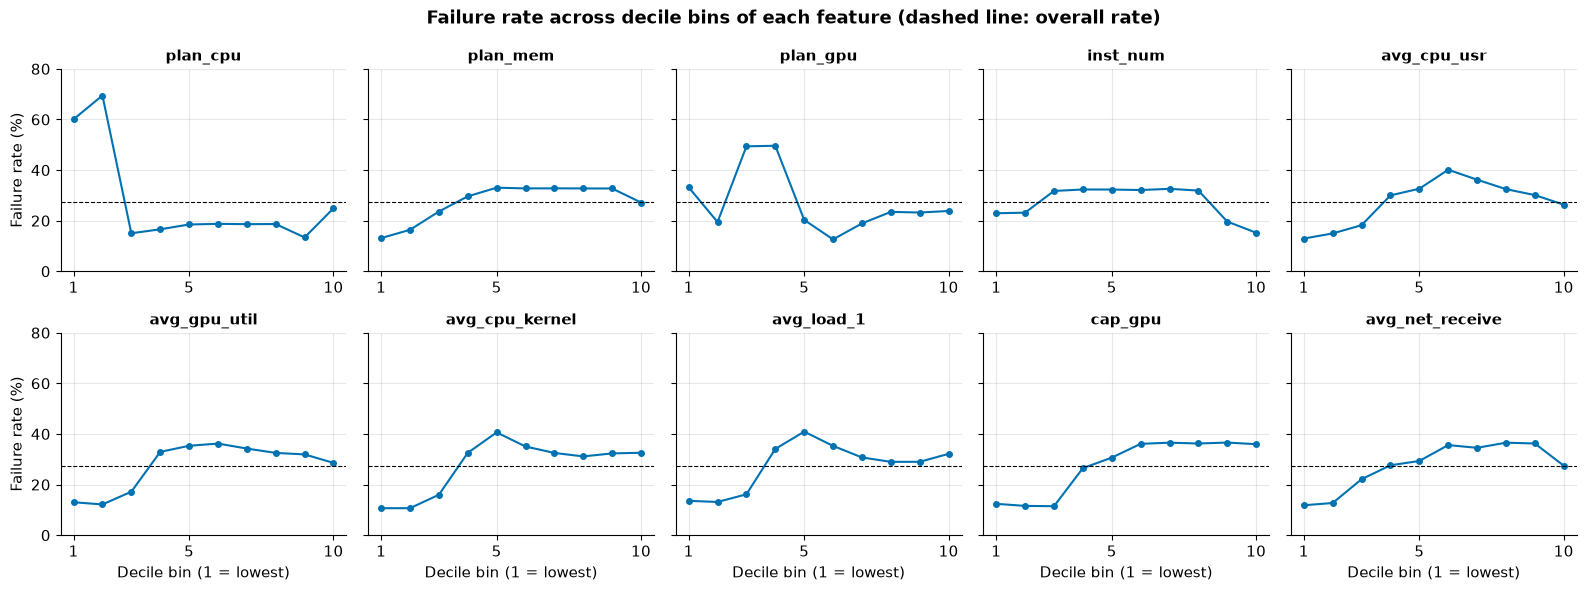

Takeaway: every feature moves the failure rate on its own, and `plan_cpu` moves it most, by 56 percentage points between its lowest and highest bins. Ties in the request features (many tasks ask for exactly 6 cores, for example) make some bins look flat.

In [6]:
def failure_by_decile(tasks, feature, q=10):
    """Failure rate and bin midpoint (median feature value) per quantile bin of ``feature``."""
    bins = pd.qcut(tasks[feature].rank(method="first"), q, labels=False)
    g = tasks.groupby(bins).agg(mid=(feature, "median"), rate=("label", "mean"))
    return g


def plot_deciles(axes, tasks):
    """Small multiples: failure rate per decile bin for each feature."""
    overall = tasks["label"].mean()
    for ax, f in zip(axes.ravel(), FEATURES):
        g = failure_by_decile(tasks, f)
        ax.plot(np.arange(1, len(g) + 1), g["rate"] * 100, "o-", color=BLUE, ms=4)
        ax.axhline(overall * 100, color=BLACK, ls="--", lw=0.8)
        ax.set_title(f, fontsize=11)
        ax.set_xticks([1, 5, 10])
        ax.set_ylim(0, 80)
    for ax in axes[-1]:
        ax.set_xlabel("Decile bin (1 = lowest)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Failure rate (%)")


fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=True)
plot_deciles(axes, tasks)
fig.suptitle("Failure rate across decile bins of each feature (dashed line: overall rate)", fontweight="bold")
plt.tight_layout()
plt.show()
spread = {f: np.ptp(failure_by_decile(tasks, f)["rate"]) for f in FEATURES}
best = max(spread, key=spread.get)
say(f"Takeaway: every feature moves the failure rate on its own, and `{best}` moves it most, by "
    f"{spread[best] * 100:.0f} percentage points between its lowest and highest bins. Ties in the request features "
    "(many tasks ask for exactly 6 cores, for example) make some bins look flat.")

## 4. A random-split baseline: logistic regression and LightGBM

The usual recipe: a stratified 70/15/15 split of tasks, clipping and scaling fitted on the training part only, a
small hyperparameter search scored on validation ROC-AUC, and one look at the test set at the end. ROC-AUC is the
probability that a random failed task scores above a random successful one (0.5 is chance).

In [7]:
def fit_lgbm(Xtr, ytr, Xva, yva, params, rounds=MAX_ROUNDS):
    """Train LightGBM with early stopping on validation AUC; return the booster."""
    dtr = lgb.Dataset(Xtr, label=ytr, feature_name=FEATURES, free_raw_data=False)
    dva = lgb.Dataset(Xva, label=yva, reference=dtr)
    return lgb.train({**LGBM_BASE, **params}, dtr, num_boost_round=rounds, valid_sets=[dva],
                     callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])


split = random_split(y)
scaler = Scaler().fit(tasks.loc[split["train"], FEATURES])
X = {k: scaler.transform(tasks.loc[idx, FEATURES]) for k, idx in split.items()}
Y = {k: y[idx] for k, idx in split.items()}
print({k: len(v) for k, v in split.items()})

t0 = time.perf_counter()
lr_model, lr_c = fit_lr(X["train"], Y["train"], X["val"], Y["val"])
grid_rows = []
for params in LGBM_GRID:
    booster = fit_lgbm(X["train"], Y["train"], X["val"], Y["val"], params)
    grid_rows.append({**params, "best_iteration": booster.best_iteration,
                      "val_auc": booster.best_score["valid_0"]["auc"], "booster": booster})
grid = pd.DataFrame(grid_rows)
display(grid.drop(columns="booster").round(4))
best_row = grid.loc[grid["val_auc"].idxmax()]
lgbm = best_row["booster"]
LGBM_PARAMS = {"num_leaves": int(best_row["num_leaves"]), "min_child_samples": int(best_row["min_child_samples"])}
print(f"chosen LightGBM: {LGBM_PARAMS}; logistic regression C = {lr_c}; fitting took {time.perf_counter() - t0:.0f} s")

{'train': 377870, 'val': 80973, 'test': 80973}


,num_leaves,min_child_samples,best_iteration,val_auc
0,31,20,1998,0.8855
1,127,20,1946,0.8979


chosen LightGBM: {'num_leaves': 127, 'min_child_samples': 20}; logistic regression C = 0.01; fitting took 102 s


In [8]:
p_lgbm = lgbm.predict(X["test"], num_iteration=lgbm.best_iteration)
p_lr = lr_model.predict_proba(X["test"])[:, 1]
res = pd.DataFrame([("logistic regression", *bootstrap_auc(Y["test"], p_lr)),
                    ("LightGBM", *bootstrap_auc(Y["test"], p_lgbm))],
                   columns=["model", "test ROC-AUC", "95% CI low", "95% CI high"]).set_index("model")
display(res.round(3))
auc_lgbm_random, auc_lr_random = res.loc["LightGBM", "test ROC-AUC"], res.loc["logistic regression", "test ROC-AUC"]
say(f"Takeaway: on a random split LightGBM reaches a test ROC-AUC of {auc_lgbm_random:.3f}, well above logistic "
    f"regression at {auc_lr_random:.3f}. Taken at face value, ten launch-time features predict failure well. "
    "Sections 6 and 7 test that reading.")

,test ROC-AUC,95% CI low,95% CI high
model,,,
logistic regression,0.731,0.727,0.736
LightGBM,0.900,0.898,0.903


Takeaway: on a random split LightGBM reaches a test ROC-AUC of 0.900, well above logistic regression at 0.731. Taken at face value, ten launch-time features predict failure well. Sections 6 and 7 test that reading.

## 5. Explaining the model with SHAP

SHAP assigns each feature a contribution to each prediction, in log-odds, so that the contributions plus a base
value add up to the model's output. For tree models LightGBM computes exact TreeSHAP values itself
(`pred_contrib=True`), the same algorithm as `shap.TreeExplainer`. We explain a random sample of test tasks.

max |sum of SHAP values + base - model log-odds| = 1.31e-13


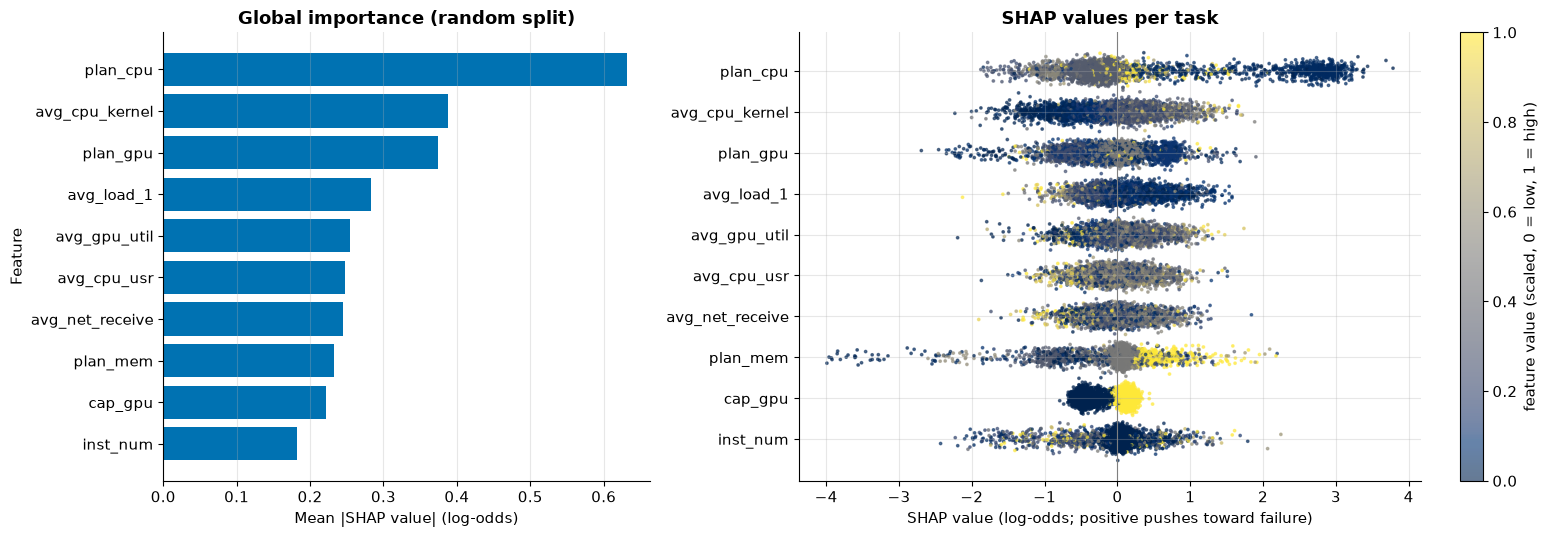

Takeaway: the model leans most on `plan_cpu`, `avg_cpu_kernel` and `plan_gpu`. The request features are set by the user and repeat across a user's jobs, so a high importance for them can mean either a real effect of the request or a way to recognise who submitted the task.

In [9]:
def tree_shap(booster, X):
    """TreeSHAP values (n, n_features) and the base value, from LightGBM's own implementation."""
    contrib = booster.predict(X, num_iteration=booster.best_iteration, pred_contrib=True)
    return contrib[:, :-1], contrib[0, -1]


def plot_importance(ax, shap_values, title, color=BLUE):
    """Mean absolute SHAP value per feature, largest at the top."""
    imp = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values()
    ax.barh(imp.index, imp.values, color=color)
    ax.set_title(title)
    ax.set_xlabel("Mean |SHAP value| (log-odds)")
    ax.set_ylabel("Feature")
    ax.grid(axis="y", visible=False)
    return imp


def plot_beeswarm(ax, shap_values, X, order, rng):
    """SHAP value per task and feature, coloured by the feature's scaled value (a beeswarm-style strip plot)."""
    for row, f in enumerate(order):
        j = FEATURES.index(f)
        jitter = rng.normal(0, 0.12, len(shap_values))
        sc = ax.scatter(shap_values[:, j], row + jitter, c=X[f].to_numpy(), cmap=SEQUENTIAL_CMAP, s=3, alpha=0.6,
                        vmin=0, vmax=1, rasterized=True)
    ax.set_yticks(range(len(order)), order)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title("SHAP values per task")
    ax.set_xlabel("SHAP value (log-odds; positive pushes toward failure)")
    plt.colorbar(sc, ax=ax, label="feature value (scaled, 0 = low, 1 = high)")


rng = np.random.default_rng(SEED)
shap_idx = rng.choice(len(X["test"]), size=min(N_SHAP, len(X["test"])), replace=False)
X_shap = X["test"].iloc[shap_idx]
sv, base = tree_shap(lgbm, X_shap)
raw_margin = lgbm.predict(X_shap, num_iteration=lgbm.best_iteration, raw_score=True)
print(f"max |sum of SHAP values + base - model log-odds| = {np.abs(sv.sum(1) + base - raw_margin).max():.2e}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
imp_random = plot_importance(axes[0], sv, "Global importance (random split)")
plot_beeswarm(axes[1], sv, X_shap, list(imp_random.index), rng)
plt.tight_layout()
plt.show()
top = list(imp_random.index[::-1][:3])
say(f"Takeaway: the model leans most on `{top[0]}`, `{top[1]}` and `{top[2]}`. The request features are set by the "
    "user and repeat across a user's jobs, so a high importance for them can mean either a real effect of the request "
    "or a way to recognise who submitted the task.")

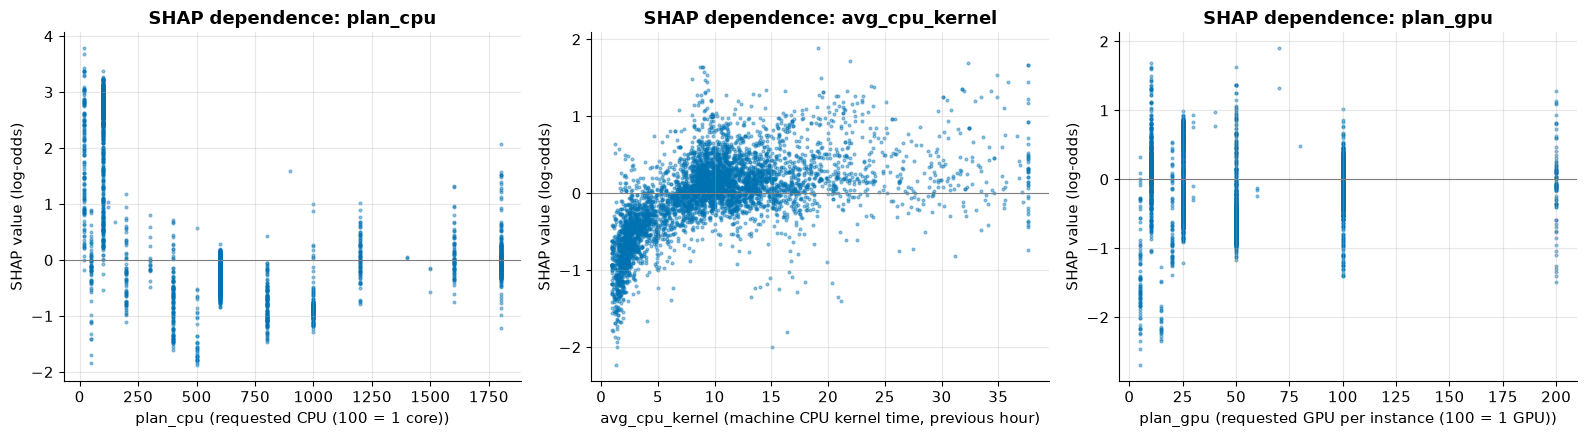

Takeaway: the dependence plots are jagged, with sharp jumps at particular request values and few smooth trends. That is what a model looks like when it memorises specific configurations, which the next two sections examine.

In [10]:
def plot_dependence(axes, shap_values, X, features, scaler):
    """SHAP value against the raw feature value, one panel per feature."""
    for ax, f in zip(axes, features):
        j = FEATURES.index(f)
        ax.scatter(scaler.to_raw(f, X[f].to_numpy()), shap_values[:, j], s=4, alpha=0.4, color=BLUE, rasterized=True)
        ax.axhline(0, color="grey", lw=0.8)
        ax.set_title(f"SHAP dependence: {f}")
        ax.set_xlabel(f"{f} ({FEATURE_NOTES[f]})")
        ax.set_ylabel("SHAP value (log-odds)")


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_dependence(axes, sv, X_shap, top, scaler)
plt.tight_layout()
plt.show()
say("Takeaway: the dependence plots are jagged, with sharp jumps at particular request values and few smooth "
    "trends. That is what a model looks like when it memorises specific configurations, which the next two sections "
    "examine.")

In [11]:
try:
    import shap

    explainer = shap.TreeExplainer(lgbm)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # shap notes a change in its output format for LightGBM
        sv_check = np.asarray(explainer.shap_values(X_shap.iloc[:200]))
    sv_check = sv_check[1] if sv_check.ndim == 3 else sv_check
    print(f"shap {shap.__version__}: max |TreeExplainer - LightGBM pred_contrib| = {np.abs(sv_check - sv[:200]).max():.2e}")
except ImportError:
    print("shap is not installed here; LightGBM's pred_contrib already gives exact TreeSHAP values")

shap 0.51.0: max |TreeExplainer - LightGBM pred_contrib| = 0.00e+00


## 6. A warning sign: exact duplicates across the split

If many test tasks have an identical feature vector in the training data, a model that memorises configurations
gets rewarded for it. Count them, and score the test set separately with and without duplicates.

In [12]:
def row_keys(df):
    """A hash per row of the ten raw features (identical vectors get identical keys)."""
    return pd.util.hash_pandas_object(df[FEATURES], index=False).to_numpy()


keys = row_keys(tasks)
in_train = np.isin(keys[split["test"]], keys[split["train"]])
dup_share = in_train.mean()
dup_auc = roc_auc_score(Y["test"][in_train], p_lgbm[in_train])
new_auc = roc_auc_score(Y["test"][~in_train], p_lgbm[~in_train])
print(f"test tasks with an exact copy of all ten features in training: {in_train.sum():,} of {len(in_train):,} "
      f"({dup_share:.1%})")
print(f"LightGBM test ROC-AUC: duplicated tasks {dup_auc:.3f}; tasks without a copy {new_auc:.3f}")
say(f"Takeaway: {dup_share:.0%} of random-split test tasks have an exact twin in training, and LightGBM scores "
    f"{dup_auc:.3f} on them against {new_auc:.3f} on the rest. Part of the headline score is recall of seen "
    "configurations.")

test tasks with an exact copy of all ten features in training: 23,683 of 80,973 (29.2%)
LightGBM test ROC-AUC: duplicated tasks 0.968; tasks without a copy 0.781


Takeaway: 29% of random-split test tasks have an exact twin in training, and LightGBM scores 0.968 on them against 0.781 on the rest. Part of the headline score is recall of seen configurations.

## 7. The honest test: users the model has never seen

A cluster operator wants a model that works for next month's jobs, including users it has not seen. A
user-grouped evaluation keeps every user's tasks inside one part of the split: five folds, each holding out about a
fifth of the users for testing, with validation users drawn from the rest. The model settings stay as chosen above.

,test tasks,test users,user 1 in test,LightGBM,logistic regression,LightGBM rounds
fold,,,,,,
0,86809,265,False,0.473,0.568,1
1,86716,278,False,0.557,0.498,57
2,86794,292,False,0.494,0.526,54
3,86750,321,False,0.430,0.782,2
4,192747,3,True,0.776,0.620,343


grouped evaluation took 92 s


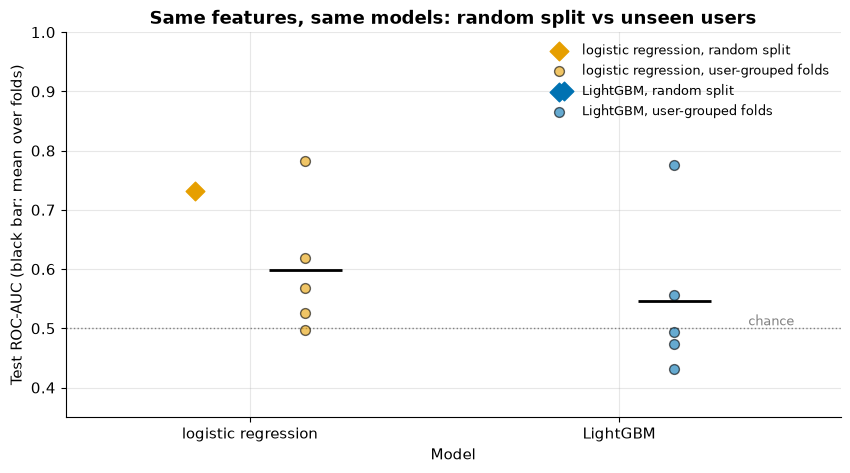

Takeaway: with users held out, LightGBM's mean test ROC-AUC falls from 0.900 to 0.546 (folds range 0.430 to 0.776); logistic regression averages 0.599. LightGBM beats logistic regression on fold(s) 1, 4; fold 4 is the one whose test set holds user 1 (3 test users, 192,747 tasks). On fold(s) 0, 3 validation AUC peaked within five boosting rounds: little of what the model learns from one group of users helps on another.

In [13]:
def grouped_scores(tasks, y, users, folds):
    """Per-fold test ROC-AUC of LightGBM and logistic regression with users held out; also returns fold models."""
    rows, models = [], []
    for k, fold in enumerate(folds):
        sc = Scaler().fit(tasks.loc[fold["train"], FEATURES])
        Xf = {p: sc.transform(tasks.loc[idx, FEATURES]) for p, idx in fold.items()}
        Yf = {p: y[idx] for p, idx in fold.items()}
        booster = fit_lgbm(Xf["train"], Yf["train"], Xf["val"], Yf["val"], LGBM_PARAMS)
        lr_m, _ = fit_lr(Xf["train"], Yf["train"], Xf["val"], Yf["val"])
        test_users = np.unique(users[fold["test"]])
        rows.append({"fold": k, "test tasks": len(fold["test"]), "test users": len(test_users),
                     "user 1 in test": bool(1 in test_users),
                     "LightGBM": roc_auc_score(Yf["test"], booster.predict(Xf["test"], num_iteration=booster.best_iteration)),
                     "logistic regression": roc_auc_score(Yf["test"], lr_m.predict_proba(Xf["test"])[:, 1]),
                     "LightGBM rounds": booster.best_iteration})
        models.append((booster, Xf["test"]))
    return pd.DataFrame(rows).set_index("fold"), models


t0 = time.perf_counter()
folds = user_grouped_folds(y, users)
gs, fold_models = grouped_scores(tasks, y, users, folds)
display(gs.round(3))
print(f"grouped evaluation took {time.perf_counter() - t0:.0f} s")


def plot_random_vs_grouped(ax, res, gs):
    """Test ROC-AUC on the random split next to each user-grouped fold, for both models."""
    models = ["logistic regression", "LightGBM"]
    for i, (m, color) in enumerate(zip(models, [ORANGE, BLUE])):
        ax.scatter([i - 0.15], [res.loc[m, "test ROC-AUC"]], marker="D", s=90, color=color, zorder=3,
                   label=f"{m}, random split")
        ax.scatter(np.full(len(gs), i + 0.15), gs[m], s=50, color=color, alpha=0.6, edgecolor=BLACK, zorder=3,
                   label=f"{m}, user-grouped folds")
        ax.hlines(gs[m].mean(), i + 0.05, i + 0.25, color=BLACK, lw=2)
    ax.axhline(0.5, color="grey", ls=":", lw=1)
    ax.text(1.35, 0.505, "chance", color="grey", fontsize=9)
    ax.set_xticks([0, 1], models)
    ax.set_xlim(-0.5, 1.6)
    ax.set_ylim(0.35, 1.0)
    ax.set_title("Same features, same models: random split vs unseen users")
    ax.set_xlabel("Model")
    ax.set_ylabel("Test ROC-AUC (black bar: mean over folds)")
    ax.legend(fontsize=9, loc="upper right")


fig, ax = plt.subplots(figsize=(10, 5))
plot_random_vs_grouped(ax, res, gs)
plt.show()
u1_fold = gs.index[gs["user 1 in test"]][0]
lgbm_wins = gs.index[gs["LightGBM"] > gs["logistic regression"]].tolist()
quick = gs.index[gs["LightGBM rounds"] <= 5].tolist()
say(f"Takeaway: with users held out, LightGBM's mean test ROC-AUC falls from {auc_lgbm_random:.3f} to "
    f"{gs['LightGBM'].mean():.3f} (folds range {gs['LightGBM'].min():.3f} to {gs['LightGBM'].max():.3f}); logistic "
    f"regression averages {gs['logistic regression'].mean():.3f}. LightGBM beats logistic regression on fold(s) "
    f"{', '.join(map(str, lgbm_wins)) or 'none'}; fold {u1_fold} is the one whose test set holds user 1 "
    f"({gs.loc[u1_fold, 'test users']} test users, {gs.loc[u1_fold, 'test tasks']:,} tasks). On fold(s) "
    f"{', '.join(map(str, quick)) or 'none'} validation AUC peaked within five boosting rounds: little of what the "
    "model learns from one group of users helps on another.")

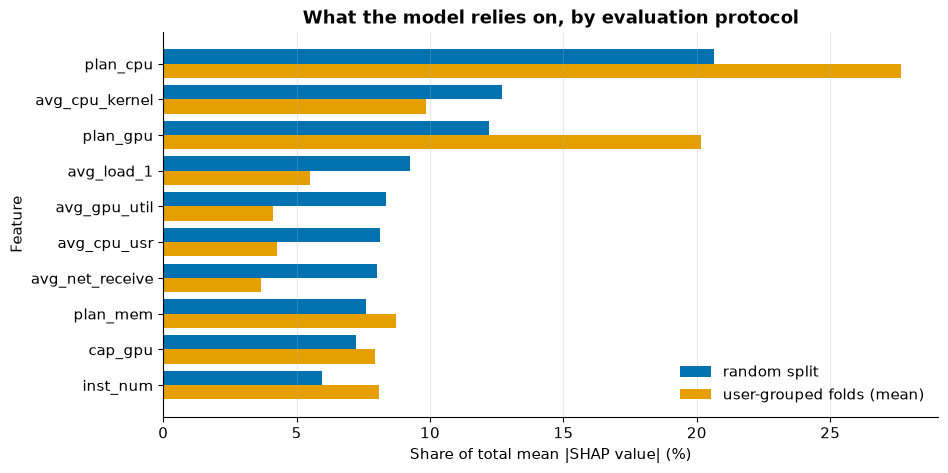

Takeaway: models trained without the test users spread their attention differently; the largest gain in share is `plan_gpu` (+8 points) and the largest loss is `avg_net_receive` (-4 points). Importance measured under a random split describes the users the model was trained on.

In [14]:
def grouped_importance(fold_models, n=N_SHAP, seed=SEED):
    """Mean |SHAP| per feature averaged over the user-grouped fold models (each on its own test users)."""
    rng = np.random.default_rng(seed)
    imps = []
    for booster, Xt in fold_models:
        idx = rng.choice(len(Xt), size=min(n // len(fold_models), len(Xt)), replace=False)
        s, _ = tree_shap(booster, Xt.iloc[idx])
        imps.append(np.abs(s).mean(axis=0))
    return pd.Series(np.mean(imps, axis=0), index=FEATURES)


imp_grouped = grouped_importance(fold_models)
share = pd.DataFrame({"random split": imp_random / imp_random.sum(), "user-grouped": imp_grouped / imp_grouped.sum()})
share = share.sort_values("random split")
fig, ax = plt.subplots(figsize=(10, 5))
yy = np.arange(len(share))
ax.barh(yy + 0.2, share["random split"] * 100, 0.4, color=BLUE, label="random split")
ax.barh(yy - 0.2, share["user-grouped"] * 100, 0.4, color=ORANGE, label="user-grouped folds (mean)")
ax.set_yticks(yy, share.index)
ax.set_title("What the model relies on, by evaluation protocol")
ax.set_xlabel("Share of total mean |SHAP value| (%)")
ax.set_ylabel("Feature")
ax.legend()
ax.grid(axis="y", visible=False)
plt.show()
shift = (share["user-grouped"] - share["random split"]).sort_values()
say(f"Takeaway: models trained without the test users spread their attention differently; the largest gain in share "
    f"is `{shift.index[-1]}` ({shift.iloc[-1] * 100:+.0f} points) and the largest loss is `{shift.index[0]}` "
    f"({shift.iloc[0] * 100:+.0f} points). Importance measured under a random split describes the users the model "
    "was trained on.")

In [15]:
save_cover(lambda ax: plot_random_vs_grouped(ax, res, gs))
print("saved cover.png (random split vs user-grouped ROC-AUC)")

saved cover.png (random split vs user-grouped ROC-AUC)


## 8. What we found

In [16]:
say(f"""- On a random task-level split, LightGBM predicts failure with a test ROC-AUC of {auc_lgbm_random:.3f}
  (logistic regression: {auc_lr_random:.3f}), from ten features known when a task launches.
- {dup_share:.0%} of those test tasks have an exact copy of all ten features in training, and the model scores
  {dup_auc:.3f} on them against {new_auc:.3f} on the rest.
- Holding users out drops LightGBM to a mean of {gs['LightGBM'].mean():.3f} over five folds, with logistic
  regression at {gs['logistic regression'].mean():.3f}.
- One user submits {u1['share_of_tasks']:.0%} of the tasks and {u1['share_of_failures']:.0%} of the failures, so a
  random split mostly tests how well the model knows that user.""")

- On a random task-level split, LightGBM predicts failure with a test ROC-AUC of 0.900
  (logistic regression: 0.731), from ten features known when a task launches.
- 29% of those test tasks have an exact copy of all ten features in training, and the model scores
  0.968 on them against 0.781 on the rest.
- Holding users out drops LightGBM to a mean of 0.546 over five folds, with logistic
  regression at 0.599.
- One user submits 31% of the tasks and 55% of the failures, so a
  random split mostly tests how well the model knows that user.

### Limitations

- The features are coarse: four requests, the machine's GPU count and five averages of other jobs' telemetry. No
  job code, framework version or user history is available.
- One seed and a two-setting grid for LightGBM; the KANVAS study uses five seeds, a larger grid and paired bootstrap
  tests (see the repository and `results/analysis/full/`).
- "Failed" in the trace mixes user errors, infrastructure faults and kills; the label does not say which.

### Ideas to try

- Add user history features (a user's past failure rate, computed only from earlier tasks) and evaluate on a
  time-ordered split.
- Constrain LightGBM (fewer leaves, monotone constraints, interaction limits) and see whether the grouped score rises.
- Remove exact duplicates before splitting and compare the random-split score.

### The series

1. [Alibaba PAI GPU trace 2020: a complete EDA](https://www.kaggle.com/code/swapnilshukla007/alibaba-pai-gpu-trace-2020-a-complete-eda)
2. [Where cluster GPUs sit idle: utilization, over-requesting and fragmentation](https://www.kaggle.com/code/swapnilshukla007/where-cluster-gpus-sit-idle)
3. Predicting GPU task failure: a LightGBM baseline explained with SHAP (this notebook)
4. [Kolmogorov-Arnold additive models from scratch: B-spline edge functions in PyTorch](https://www.kaggle.com/code/swapnilshukla007/kolmogorov-arnold-additive-models-from-scratch)
5. [Reading the splines: KAAM shape functions vs SHAP on the same tasks](https://www.kaggle.com/code/swapnilshukla007/reading-the-splines-kaam-curves-vs-shap)

If something here is wrong or unclear, a comment helps more than anything; an upvote helps others find it.